# KNN model

In [1]:
#  Step 1: Import required lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# step 2: load the dataset
df  = pd.read_csv("C:\\Users\\NAYAN\\Downloads\\knn_regression_dataset.csv")

In [4]:
# Step 3: data Exploration
df.head()


,age,income,loan_amount,credit_score,city,employment_type,target
0,56,25903.305196,286348.192562,789.476075,Chennai,Salaried,158793.631698
1,69,53051.954538,180018.190719,596.334039,Chennai,Salaried,115596.093965
2,46,38654.738821,211234.236288,611.531000,Chennai,Salaried,127231.057638
3,32,28666.194356,246629.541594,710.171152,Chennai,Unemployed,145102.187078
4,60,40301.406736,129081.713353,622.900855,Hyderabad,Unemployed,110623.128404


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              1000 non-null   int64  
 1   income           970 non-null    float64
 2   loan_amount      970 non-null    float64
 3   credit_score     971 non-null    float64
 4   city             1000 non-null   object 
 5   employment_type  1000 non-null   object 
 6   target           1000 non-null   float64
dtypes: float64(4), int64(1), object(2)
memory usage: 54.8+ KB


In [6]:
df.describe()

,age,income,loan_amount,credit_score,target
count,1000.00000,970.000000,970.000000,971.000000,1000.000000
mean,43.81900,52924.860515,204508.531872,649.422223,125258.332699
std,14.99103,21236.060048,58239.083910,71.104784,31423.294558
min,18.00000,6556.169327,49024.392209,440.620482,40800.918241
25%,31.00000,40854.271568,168890.053957,600.334270,105707.679044
50%,44.00000,51119.925190,200190.693629,649.978043,123651.542971
75%,56.00000,61104.364633,235458.241233,696.092859,141801.468844
max,69.00000,220985.397589,597644.058452,858.968130,333440.450713


In [7]:
df.isnull().sum()

age                 0
income             30
loan_amount        30
credit_score       29
city                0
employment_type     0
target              0
dtype: int64

<Axes: ylabel='age'>

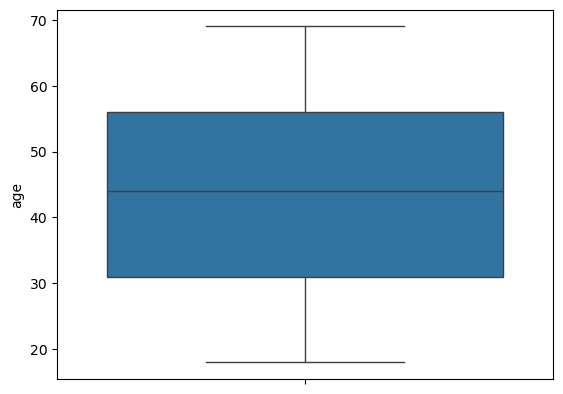

In [8]:
# Step 4: Data Visualization

sns.boxplot(df['age'])

In [9]:
# handle the missing value of columsn

# find the median of income , credit score and loan amount columns

income_median = df['income'].median()
credit_score_median = df['credit_score'].median()
loan_amount_median = df['loan_amount'].median()


# handled the missing columns with median values
df['income'].fillna(income_median, inplace=True)
df['credit_score'].fillna(credit_score_median, inplace=True)
df['loan_amount'].fillna(loan_amount_median, inplace=True)

C:\Users\NAYAN\AppData\Local\Temp\ipykernel_21464\742716296.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['income'].fillna(income_median, inplace=True)
C:\Users\NAYAN\AppData\Local\Temp\ipykernel_21464\742716296.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exa

In [10]:
df.isnull().sum()

age                0
income             0
loan_amount        0
credit_score       0
city               0
employment_type    0
target             0
dtype: int64

In [11]:
df['city'].value_counts()

city
Hyderabad    260
Chennai      259
Bangalore    256
Mumbai       225
Name: count, dtype: int64

In [13]:
# get_dummies method is used to convert categorical data into numerical data

# Convert categorical columns into numerical columns

categorical_cols = ['city', 'employment_type']

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df.head()


,age,income,loan_amount,credit_score,target,city_Chennai,city_Hyderabad,city_Mumbai,employment_type_Self-Employed,employment_type_Unemployed
0,56,25903.305196,286348.192562,789.476075,158793.631698,1,0,0,0,0
1,69,53051.954538,180018.190719,596.334039,115596.093965,1,0,0,0,0
2,46,38654.738821,211234.236288,611.531000,127231.057638,1,0,0,0,0
3,32,28666.194356,246629.541594,710.171152,145102.187078,1,0,0,0,1
4,60,40301.406736,129081.713353,622.900855,110623.128404,0,1,0,0,1


In [14]:
df.head()

,age,income,loan_amount,credit_score,target,city_Chennai,city_Hyderabad,city_Mumbai,employment_type_Self-Employed,employment_type_Unemployed
0,56,25903.305196,286348.192562,789.476075,158793.631698,1,0,0,0,0
1,69,53051.954538,180018.190719,596.334039,115596.093965,1,0,0,0,0
2,46,38654.738821,211234.236288,611.531000,127231.057638,1,0,0,0,0
3,32,28666.194356,246629.541594,710.171152,145102.187078,1,0,0,0,1
4,60,40301.406736,129081.713353,622.900855,110623.128404,0,1,0,0,1


In [15]:
#  divide the data into independent and dependent features
X = df.drop('target', axis=1)
y = df['target']

In [16]:
# scale the data using MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X = scaler.fit_transform(X)

In [17]:
X.shape

(1000, 9)

In [19]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=['target'])
y = df['target']

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (800, 9)
Testing data: (200, 9)


In [20]:
# apply the lasso regression model on the dataset
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

# find the score of features using lasso regression model
lasso_score = lasso_model.score(X_test, y_test)
print("Lasso Regression Score:", lasso_score*100)




Lasso Regression Score: 88.50417116016042


In [21]:
# split the data into training and testing data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
# Train the KNN model
from sklearn.neighbors import KNeighborsRegressor

# create the KNN model with n_neighbors=5
knn_model = KNeighborsRegressor(n_neighbors=2)

# train the model with training data
knn_model.fit(X_train, y_train)

#predict the target values for testing data
y_pred = knn_model.predict(X_test)


In [ ]:
# model evaluation
from sklearn.metrics import mean_squared_error, r2_score

# find the mean squared error and r2 score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

#print the mean squared error and r2 score
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Squared Error: 537621545.7283837
R2 Score: 0.484692193300427


In [27]:

from sklearn.metrics import mean_squared_error, r2_score

print("Metrics imported successfully!")


Metrics imported successfully!


In [28]:
# elbow method to find the optimal value of k
mse_values = []
k_range = range(1, 21)

for k in k_range:
    knn_model = KNeighborsRegressor(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mse_values.append(mse)

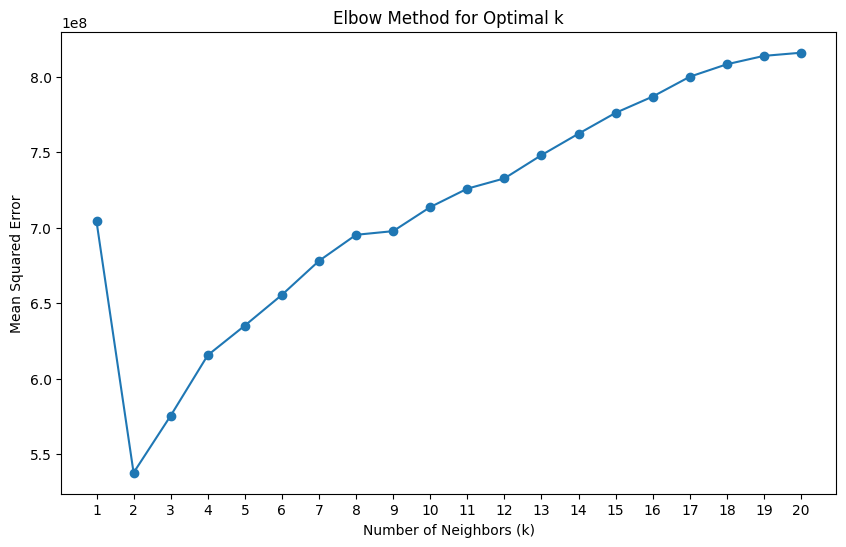

In [ ]:
# make the plot for elbow method
plt.figure(figsize=(10, 6))

plt.plot(k_range, mse_values, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Squared Error')
plt.xticks(k_range)
plt.show()

In [24]:
# check the training and testing score of the model
train_score = knn_model.score(X_train, y_train)
test_score = knn_model.score(X_test, y_test)

print("KNN Training Score:", train_score*100)
print("KNN Testing Score:", test_score*100)

KNN Training Score: 100.0
KNN Testing Score: 76.32102580989051


In [25]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)



In [29]:
# find tge mean squared error and r2 score for Decision Tree model

mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Mean Squared Error:", mse_dt)
print("Decision Tree R2 Score:", r2_dt)

Decision Tree Mean Squared Error: 400139504.14416367
Decision Tree R2 Score: 0.6164681049472723
